In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('telco_churn_unclean.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,Yes,DSL,No,...,No,No,No,No,month to month,Yes,Electronic check,$29.85,NaN,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.7,151.65,Yes


In [ ]:
df["TotalCharges"] = df["TotalCharges"].replace(" ","0")
df["TotalCharges"] = df["TotalCharges"].astype("float")

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7048 entries, 0 to 7047
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7048 non-null   object 
 1   gender            7048 non-null   object 
 2   SeniorCitizen     7048 non-null   int64  
 3   Partner           7048 non-null   object 
 4   Dependents        7048 non-null   object 
 5   tenure            7048 non-null   int64  
 6   PhoneService      7048 non-null   object 
 7   MultipleLines     7048 non-null   object 
 8   InternetService   7048 non-null   object 
 9   OnlineSecurity    7048 non-null   object 
 10  OnlineBackup      7048 non-null   object 
 11  DeviceProtection  7048 non-null   object 
 12  TechSupport       7048 non-null   object 
 13  StreamingTV       7048 non-null   object 
 14  StreamingMovies   7048 non-null   object 
 15  Contract          7048 non-null   object 
 16  PaperlessBilling  7048 non-null   object 


In [ ]:
df.isnull()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7043,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
7044,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
7045,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
7046,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
df["customerID"].duplicated().sum()

np.int64(5)

In [ ]:
df = df.drop_duplicates(subset='customerID')
df.shape

(7043, 21)

In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df = df.drop_duplicates(subset='customerID')
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('telco_churn_unclean.csv')
df.shape


(7048, 21)

In [ ]:
df = df.drop_duplicates(subset='customerID')
df.shape

(7043, 21)

In [ ]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [ ]:
df[['MonthlyCharges','TotalCharges']].dtypes

,0
MonthlyCharges,object
TotalCharges,object


In [ ]:
for col in ['MonthlyCharges', 'TotalCharges']:
    bad = df[pd.to_numeric(df[col], errors='coerce').isnull()][col]
    print(col, '->', bad.unique()[:10])

MonthlyCharges -> ['$29.85' '$29.75' '$105.5' '$19.8' '$90.25' '$99.9' '$20.75' '$64.15'
 '$99.65' '$54.4']
TotalCharges -> [nan ' ']


In [ ]:
df['MonthlyCharges'] = pd.to_numeric(df['MonthlyCharges'], errors='coerce')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(df[['MonthlyCharges','TotalCharges']].dtypes)
print(df[['MonthlyCharges','TotalCharges']].isnull().sum())

MonthlyCharges    float64
TotalCharges      float64
dtype: object
MonthlyCharges    1007
TotalCharges       133
dtype: int64


In [ ]:
df = pd.read_csv('telco_churn_unclean.csv')
df = df.drop_duplicates(subset='customerID')

for col in ['MonthlyCharges', 'TotalCharges']:
    df[col] = df[col].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False).str.strip()
    df[col] = pd.to_numeric(df[col], errors='coerce')

print(df[['MonthlyCharges', 'TotalCharges']].dtypes)
print(df[['MonthlyCharges', 'TotalCharges']].isnull().sum())

MonthlyCharges    float64
TotalCharges      float64
dtype: object
MonthlyCharges      0
TotalCharges      133
dtype: int64


In [ ]:
missing = df[df['TotalCharges'].isnull()]
print(missing['tenure'].value_counts().head(10))
missing[['customerID','tenure','MonthlyCharges','TotalCharges']].head(10)

tenure
1    122
0     11
Name: count, dtype: int64


,customerID,tenure,MonthlyCharges,TotalCharges
0,7590-VHVEG,1,29.85,NaN
20,8779-QRDMV,1,39.65,NaN
70,2273-QCKXA,1,49.05,NaN
80,5919-TMRGD,1,94.26,NaN
100,6380-ARCEH,1,20.20,NaN
180,6317-YPKDH,1,29.95,NaN
185,1024-GUALD,1,24.80,NaN
295,8203-XJZRC,1,20.25,NaN
310,1098-TDVUQ,1,19.25,NaN
345,0021-IKXGC,1,72.10,NaN


In [ ]:
df['TotalCharges'].isnull().sum()

np.int64(0)

In [ ]:
df = pd.read_csv('telco_churn_unclean.csv')
df = df.drop_duplicates(subset='customerID')

for col in ['MonthlyCharges', 'TotalCharges']:
    df[col] = df[col].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False).str.strip()
    df[col] = pd.to_numeric(df[col], errors='coerce')

df['TotalCharges'] = df['TotalCharges'].fillna(df['MonthlyCharges'] * df['tenure'])

print(df.shape)
print(df[['MonthlyCharges', 'TotalCharges']].isnull().sum())

(7043, 21)
MonthlyCharges    0
TotalCharges      0
dtype: int64


In [ ]:
for col in ['gender', 'Contract', 'PaymentMethod', 'InternetService', 'Churn']:
    print(col, '->', df[col].unique())

gender -> ['Female' 'Male']
Contract -> ['month to month' 'One year' 'Month-to-month' 'Two year']
PaymentMethod -> ['Electronic check ' 'Mailed check' 'Bank transfer (automatic)'
 'Electronic check' 'Credit card (automatic)' 'Mailed check '
 'Credit card (automatic) ' 'Bank transfer (automatic) ']
InternetService -> ['DSL' 'Fiber optic' 'No']
Churn -> ['No' 'Yes']


In [ ]:
df['Contract'] = df['Contract'].str.strip().replace({'month to month': 'Month-to-month'})
df['PaymentMethod'] = df['PaymentMethod'].str.strip()

print(df['Contract'].unique())
print(df['PaymentMethod'].unique())

['Month-to-month' 'One year' 'Two year']
['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']


In [ ]:
print(df['SeniorCitizen'].unique())
df[['tenure', 'MonthlyCharges', 'TotalCharges']].describe()

[0 1]


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.760605,2279.736421
std,24.559481,30.089912,2266.792421
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.300000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


In [ ]:
df.to_csv('telco_churn_clean.csv', index=False)

In [ ]:
df.to_csv('telco_churn_clean.csv', index=False)

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64


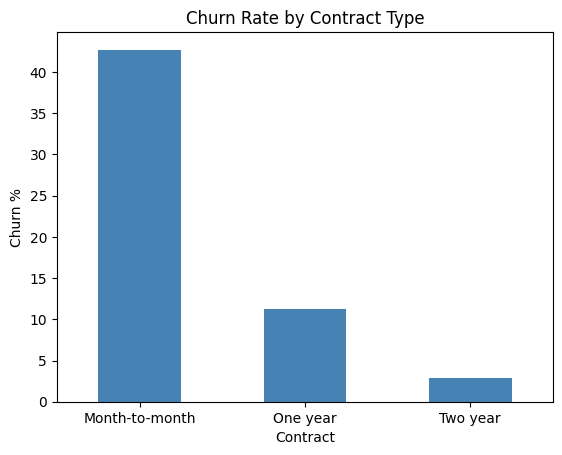

In [ ]:
churn_rate = df.groupby('Contract')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)
print(churn_rate.round(1))

churn_rate.plot(kind='bar', color='steelblue')
plt.title('Churn Rate by Contract Type')
plt.ylabel('Churn %')
plt.xticks(rotation=0)
plt.show()

TenureGroup
0-12 months     47.4
13-24 months    28.7
25-48 months    20.4
49-72 months     9.5
Name: Churn, dtype: float64


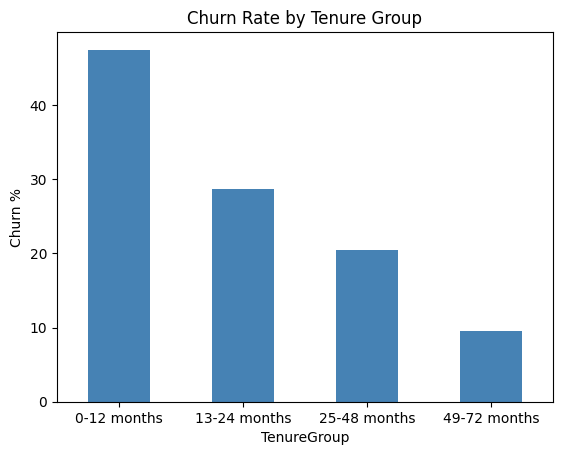

In [ ]:
df['TenureGroup'] = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 72],
                           labels=['0-12 months', '13-24 months', '25-48 months', '49-72 months'])

tenure_churn = df.groupby('TenureGroup', observed=True)['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)
print(tenure_churn.round(1))

tenure_churn.plot(kind='bar', color='steelblue')
plt.title('Churn Rate by Tenure Group')
plt.ylabel('Churn %')
plt.xticks(rotation=0)
plt.show()

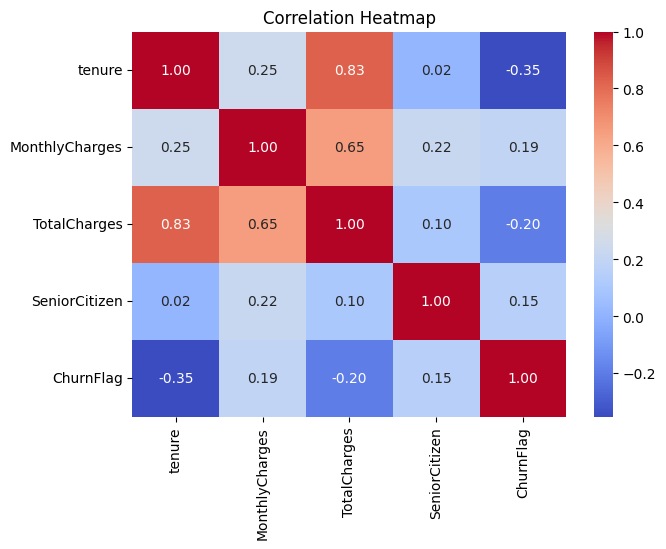

In [ ]:
df['ChurnFlag'] = (df['Churn'] == 'Yes').astype(int)

corr = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'ChurnFlag']].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

In [ ]:
df.to_csv('telco_churn_clean.csv', index=False)

In [ ]:
 import sqlite3
from google.colab import files

conn = sqlite3.connect('churn.db')
df.drop(columns=['TenureGroup', 'ChurnFlag'], errors='ignore').to_sql('churn', conn, index=False, if_exists='replace')
conn.close()

files.download('churn.db')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>